In [1]:
import csv
import json
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


ROOT = Path.cwd()


from IPython.display import Image, display


In [2]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 4 * 4, 64),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(64, 10),
        )

    def forward(self, inputs):
        return self.classifier(self.features(inputs))


In [3]:
def create_loaders(batch_size=50, seed=0):
    transform = transforms.Compose([transforms.Pad(padding=2), transforms.ToTensor()])
    trainset = datasets.MNIST(
        root=ROOT / "data", train=True, download=True, transform=transform
    )
    testset = datasets.MNIST(
        root=ROOT / "data", train=False, download=True, transform=transform
    )
    generator = torch.Generator().manual_seed(seed)
    trainloader = DataLoader(
        trainset, batch_size=batch_size, shuffle=True, generator=generator, num_workers=0
    )
    train_eval_loader = DataLoader(trainset, batch_size=batch_size, num_workers=0)
    testloader = DataLoader(testset, batch_size=batch_size, num_workers=0)
    return trainloader, train_eval_loader, testloader

@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    confusion = torch.zeros((10, 10), dtype=torch.int64)
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * len(labels)
        predictions = logits.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += len(labels)
        pairs = labels.cpu() * 10 + predictions.cpu()
        confusion += torch.bincount(pairs, minlength=100).reshape(10, 10)
    return total_loss / total, 100.0 * correct / total, confusion


In [4]:
def save_history(history, settings, output_dir):
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / "history.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=list(history[0]))
        writer.writeheader()
        writer.writerows(history)
    result = {
        **settings,
        "completed_epochs": len(history),
        "final_metrics": history[-1],
        "history": history,
    }
    (output_dir / "training_results.json").write_text(
        json.dumps(result, indent=2) + "\n", encoding="utf-8"
    )

    epochs = [row["epoch"] for row in history]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    axes[0].plot(epochs, [row["train_loss"] for row in history], marker="o", label="Training")
    axes[0].plot(epochs, [row["test_loss"] for row in history], marker="o", label="Test")
    axes[0].set(xlabel="Epoch", ylabel="Cross entropy loss", title="Small CNN loss")
    axes[1].plot(epochs, [row["train_accuracy"] for row in history], marker="o", label="Training")
    axes[1].plot(epochs, [row["test_accuracy"] for row in history], marker="o", label="Test")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Small CNN accuracy")
    for axis in axes:
        axis.set_xticks(epochs)
        axis.grid(alpha=0.2)
        axis.legend()
    fig.savefig(output_dir / "training_curve.png", dpi=180)
    plt.close(fig)
    return result

def save_confusion(confusion, output_dir):
    matrix = confusion.tolist()
    (output_dir / "confusion_matrix.json").write_text(
        json.dumps({"rows": "True digit", "columns": "Predicted digit", "counts": matrix}, indent=2)
        + "\n",
        encoding="utf-8",
    )
    with (output_dir / "confusion_matrix.csv").open("w", newline="", encoding="utf-8") as stream:
        writer = csv.writer(stream)
        writer.writerow(["True digit"] + list(range(10)))
        writer.writerows([[digit] + row for digit, row in enumerate(matrix)])

    fig, axis = plt.subplots(figsize=(8, 7), layout="constrained")
    image = axis.imshow(confusion.numpy(), cmap="Blues")
    fig.colorbar(image, ax=axis, label="Number of images")
    axis.set(
        xticks=range(10),
        yticks=range(10),
        xlabel="Predicted digit",
        ylabel="True digit",
        title="Small CNN test confusion matrix",
    )
    threshold = confusion.max().item() / 2
    for row in range(10):
        for column in range(10):
            value = matrix[row][column]
            axis.text(
                column,
                row,
                str(value),
                ha="center",
                va="center",
                color="white" if value > threshold else "black",
                fontsize=9,
            )
    fig.savefig(output_dir / "confusion_matrix.png", dpi=180)
    plt.close(fig)


In [5]:
def run_training(epochs=10, batch_size=50, learning_rate=0.001, seed=0, verbose=True):
    if epochs < 1 or batch_size < 1 or learning_rate <= 0:
        raise ValueError("Invalid training settings")
    torch.set_num_threads(4)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)
    device = torch.device("cpu")
    trainloader, train_eval_loader, testloader = create_loaders(batch_size, seed)
    model = SmallCNN().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    output_dir = ROOT / "results" / "q2_cnn"
    history = []
    settings = {
        "model": "Small CNN",
        "dataset": "MNIST",
        "training_samples": len(trainloader.dataset),
        "test_samples": len(testloader.dataset),
        "input_shape": [1, 32, 32],
        "input_padding": 2,
        "pixel_range": [0, 1],
        "augmentation": False,
        "activation": "relu",
        "pooling": "max",
        "batch_normalization": True,
        "dropout": 0.25,
        "convolution_channels": [1, 8, 16, 32],
        "convolution_kernel_size": 3,
        "classifier_sizes": [512, 64, 10],
        "output": "logits",
        "parameter_count": sum(parameter.numel() for parameter in model.parameters()),
        "loss": "cross entropy",
        "optimizer": "Adam",
        "learning_rate": learning_rate,
        "epochs": epochs,
        "batch_size": batch_size,
        "seed": seed,
        "device": str(device),
        "torch_threads": 4,
        "training_shuffle": True,
        "epoch_metrics": "Full training and test sets evaluated after each epoch",
        "accuracy_units": "percent",
    }
    for epoch in range(1, epochs + 1):
        model.train()
        for images, labels in trainloader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Training loss is not finite")
            loss.backward()
            optimizer.step()
        train_loss, train_accuracy, _ = evaluate(model, train_eval_loader, criterion, device)
        test_loss, test_accuracy, confusion = evaluate(model, testloader, criterion, device)
        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                "train_accuracy": train_accuracy,
                "test_loss": test_loss,
                "test_accuracy": test_accuracy,
            }
        )
        result = save_history(history, settings, output_dir)
        if verbose:
            print(
                f"Epoch {epoch} of {epochs}: training accuracy {train_accuracy:.2f}%, "
                f"test accuracy {test_accuracy:.2f}%, training loss {train_loss:.4f}, "
                f"test loss {test_loss:.4f}",
                flush=True,
            )

    save_confusion(confusion, output_dir)
    torch.save(
        {"model_state_dict": model.state_dict(), "settings": settings},
        output_dir / "cnn_weights.pt",
    )
    return result


In [6]:
result = run_training(verbose=False)


Training accuracy: 99.50%
Test accuracy: 98.82%


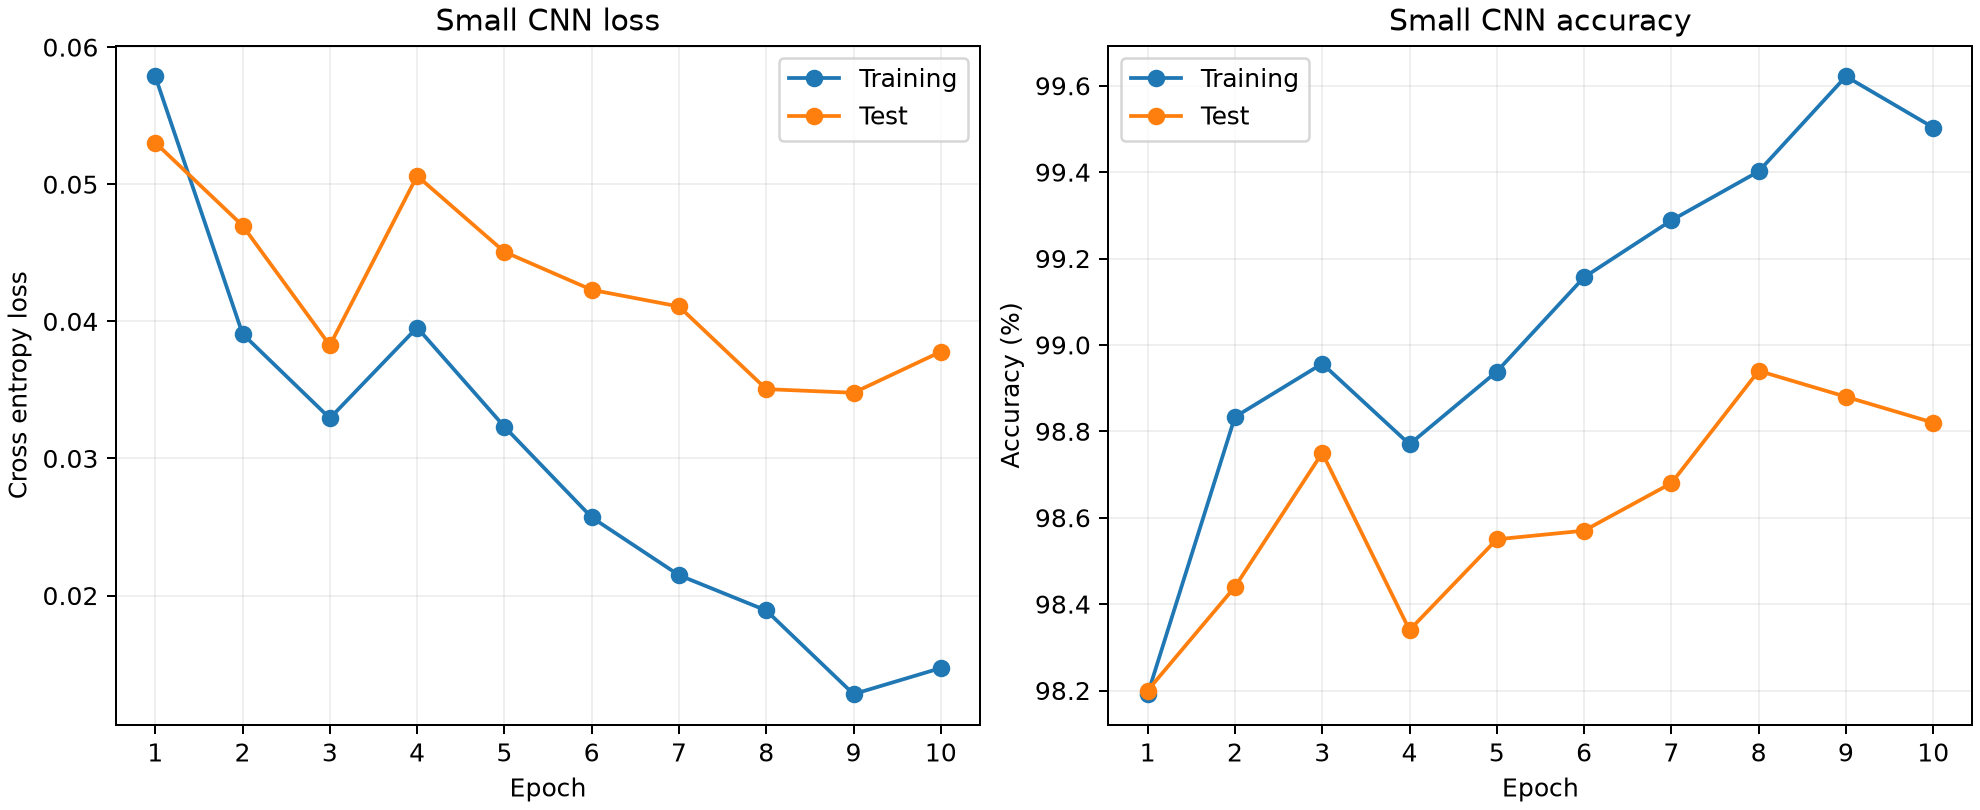

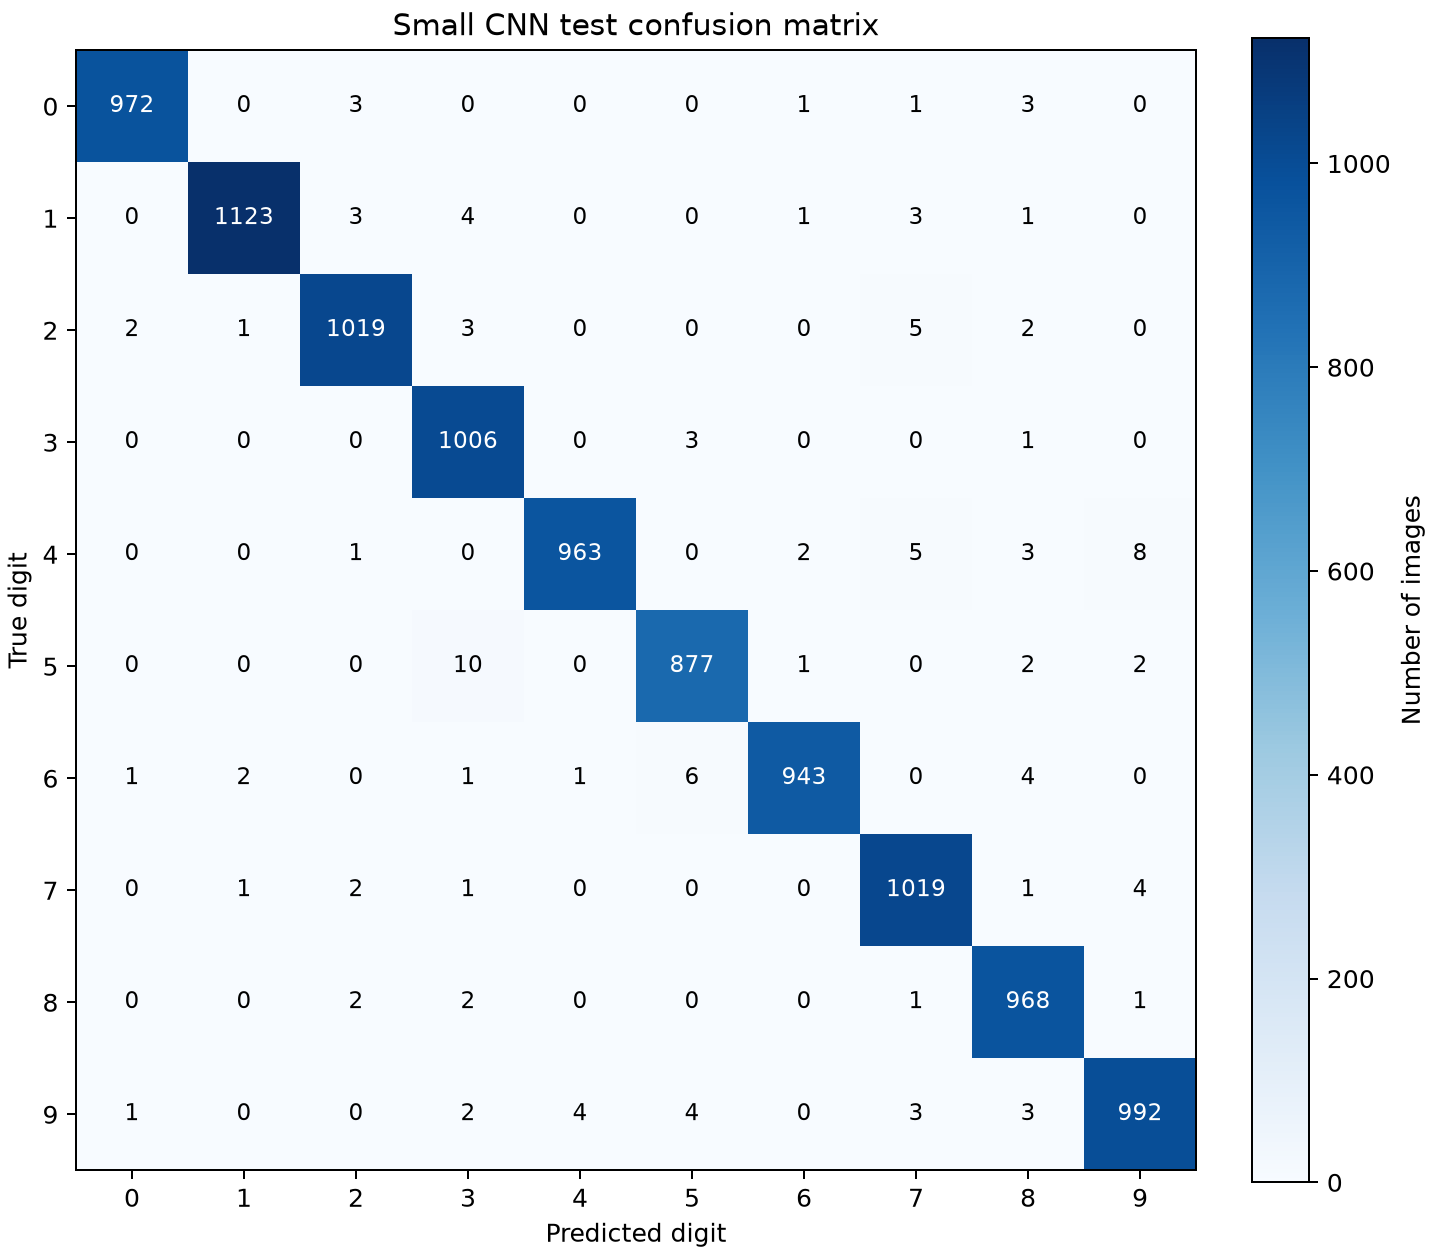

In [7]:
final = result["final_metrics"]
print(f"Training accuracy: {final['train_accuracy']:.2f}%")
print(f"Test accuracy: {final['test_accuracy']:.2f}%")
display(Image(filename=str(ROOT / "results/q2_cnn/training_curve.png"), width=900))
display(Image(filename=str(ROOT / "results/q2_cnn/confusion_matrix.png"), width=650))
